# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Annie Nguyen, Anh Bach, Sritha Alluri

**Date:** 11/16/2026

**Q1**

In [1]:
# List of imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LinearRegression

# Loading the data
df = pd.read_csv("/content/heart_failure_clinical_records_dataset.csv")

# Inspect the data; shape, missing values, and duplicate rows
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# 263358.03 shows up repeatedly in platelets; it looks like a filled-in placeholder
print("platelets == 263358.03:", (df["platelets"] == 263358.03).sum())

# A couple of ages are recorded as 60.667, which is odd for an age
print("Non-integer ages:", df.loc[df["age"] % 1 != 0, "age"].tolist())

# Class balance of the target: about 2/3 survived, 1/3 died
print(df["DEATH_EVENT"].value_counts())

# Summary stats: creatinine_phosphokinase and serum_creatinine have huge maxes (skewed)
display(df.describe().T[["mean", "min", "50%", "max"]])

# Clean the data
# Drop 'time' (follow-up period): patients who died have short follow-up
# BECAUSE they died, so keeping it would leak the answer into the model
heart = df.drop(columns="time").copy()

# Round the two 60.667 ages to whole years
heart["age"] = heart["age"].round()

# Log-transform the two heavily skewed lab values so a few extreme values don't dominate the linear model (trees aren't affected by this)
heart["log_cpk"] = np.log(heart["creatinine_phosphokinase"])
heart["log_serum_creatinine"] = np.log(heart["serum_creatinine"])
heart = heart.drop(columns=["creatinine_phosphokinase", "serum_creatinine"])

# Separate target and features
y = heart["DEATH_EVENT"]
X = heart.drop(columns="DEATH_EVENT")
X.head()

Shape: (299, 13)
Missing values: 0
Duplicate rows: 0
platelets == 263358.03: 25
Non-integer ages: [60.667, 60.667]
DEATH_EVENT
0    203
1     96
Name: count, dtype: int64


,mean,min,50%,max
age,60.833893,40.0,60.0,95.0
anaemia,0.431438,0.0,0.0,1.0
creatinine_phosphokinase,581.839465,23.0,250.0,7861.0
diabetes,0.418060,0.0,0.0,1.0
ejection_fraction,38.083612,14.0,38.0,80.0
high_blood_pressure,0.351171,0.0,0.0,1.0
platelets,263358.029264,25100.0,262000.0,850000.0
serum_creatinine,1.393880,0.5,1.1,9.4
serum_sodium,136.625418,113.0,137.0,148.0
sex,0.648829,0.0,1.0,1.0


,age,anaemia,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_sodium,sex,smoking,log_cpk,log_serum_creatinine
0,75.0,0,0,20,1,265000.00,130,1,0,6.366470,0.641854
1,55.0,0,0,38,0,263358.03,136,1,0,8.969669,0.095310
2,65.0,0,0,20,0,162000.00,129,1,1,4.983607,0.262364
3,50.0,1,0,20,0,210000.00,137,1,0,4.709530,0.641854
4,65.0,1,1,20,0,327000.00,116,0,0,5.075174,0.993252


**Q2**

,Tree,Linear model
R-squared,0.167,0.138
RMSE,0.435,0.443
Accuracy,0.767,0.650


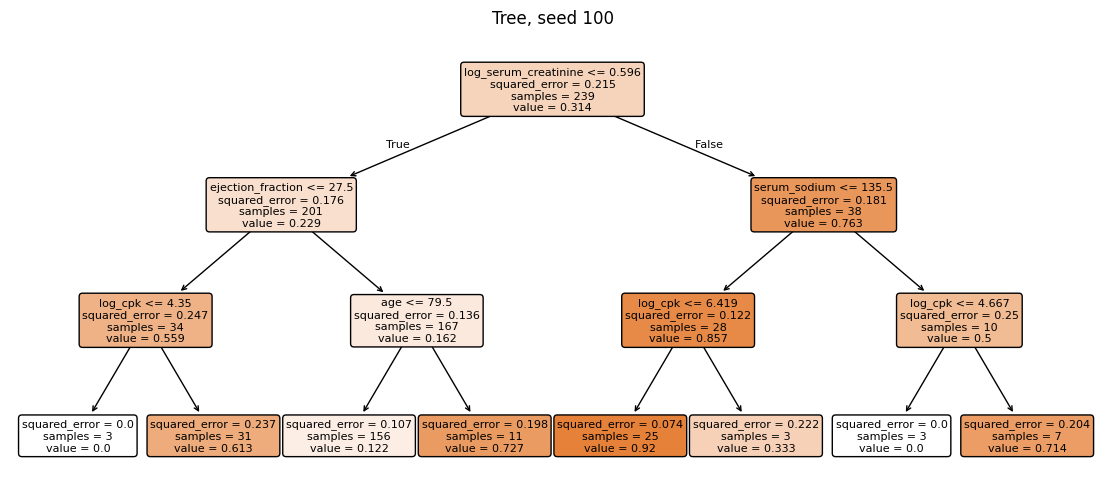

,seed 100
age,0.0088
anaemia,0.0157
diabetes,0.0111
ejection_fraction,-0.0115
high_blood_pressure,0.0729
platelets,-0.0000
serum_sodium,-0.0065
sex,-0.0802
smoking,0.0193
log_cpk,0.0294


In [2]:
# Helper: split the data and fit both models for a given seed
def fit_models(seed):
    # 80/20 train-test split; the seed controls which rows land in the test set
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=seed
    )
    # Regression tree on the 0/1 target
    tree = DecisionTreeRegressor(max_depth=3, random_state=100).fit(X_train, y_train)

    # Linear regression on the same 0/1 target
    lm = LinearRegression().fit(X_train, y_train)
    return tree, lm, X_test, y_test

# Scoring a model on the test set
def evaluate(model, X_test, y_test):
    y_hat = model.predict(X_test)
    return {
        "R-squared": round(model.score(X_test, y_test), 3),
        "RMSE": round(np.sqrt(np.mean((y_test - y_hat) ** 2)), 3),
        "Accuracy": round(np.mean((y_hat > 0.5) == y_test), 3),
    }

# Fit the main models with seed 100 (saved for reproducibility)
main_seed = 100
tree_main, lm_main, X_test_main, y_test_main = fit_models(main_seed)

# Compare test-set performance
display(pd.DataFrame({
    "Tree": evaluate(tree_main, X_test_main, y_test_main),
    "Linear model": evaluate(lm_main, X_test_main, y_test_main),
}))

# Inspect the tree
plt.figure(figsize=(14, 6))
plot_tree(tree_main, feature_names=X.columns, filled=True, rounded=True, fontsize=8)
plt.title("Tree, seed 100")
plt.show()

# Looking at the linear model coefficients
display(pd.Series(lm_main.coef_, index=X.columns).round(4).to_frame("seed 100"))

# Setting aside predictions on the seed-100 test set
tree_pred_main = tree_main.predict(X_test_main)
lm_pred_main = lm_main.predict(X_test_main)

**Q3**

R-squared          RMSE        Accuracy       
model    Linear   Tree Linear   Tree   Linear   Tree
seed                                                
100       0.138  0.167  0.443  0.435    0.650  0.767
101       0.099  0.187  0.411  0.390    0.750  0.800
102       0.265  0.105  0.413  0.456    0.700  0.683
103       0.315  0.283  0.390  0.399    0.733  0.717
104       0.102 -0.041  0.467  0.503    0.683  0.667

===== Tree, seed 100 =====
|--- log_serum_creatinine <= 0.60
|   |--- ejection_fraction <= 27.50
|   |   |--- log_cpk <= 4.35
|   |   |   |--- value: [0.00]
|   |   |--- log_cpk >  4.35
|   |   |   |--- value: [0.61]
|   |--- ejection_fraction >  27.50
|   |   |--- age <= 79.50
|   |   |   |--- value: [0.12]
|   |   |--- age >  79.50
|   |   |   |--- value: [0.73]
|--- log_serum_creatinine >  0.60
|   |--- serum_sodium <= 135.50
|   |   |--- log_cpk <= 6.42
|   |   |   |--- value: [0.92]
|   |   |--- log_cpk >  6.42
|   |   |   |--- value: [0.33]
|   |--- serum_sodium >  135.50
|   |   |--- log_cpk <= 4.67
|   |   |   |--- value: [0.00]
|   |   |--- log_cpk >  4.67
|   |   |   |--- value: [0.71]

===== Tree, seed 101 =====
|--- ejection_fraction <= 27.50
|   |--- ejection_fraction <= 22.50
|   |   |--- serum_sodium <= 138.00
|   |   |   |--- value: [1.00]
|   |   |--- serum_sodium >  138.00
|   |   |   |--- value: [0.67]
|   |--- ejection_fraction >  22.50
|   |   |--- log_cpk <= 4.20


,100,101,102,103,104
age,0.177,0.163,0.177,0.219,0.212
anaemia,0.000,0.000,0.000,0.000,0.000
diabetes,0.000,0.000,0.000,0.000,0.000
ejection_fraction,0.209,0.408,0.442,0.271,0.318
high_blood_pressure,0.000,0.000,0.000,0.061,0.000
platelets,0.000,0.000,0.118,0.000,0.036
serum_sodium,0.044,0.052,0.017,0.000,0.000
sex,0.000,0.000,0.000,0.000,0.000
smoking,0.000,0.000,0.000,0.000,0.000
log_cpk,0.142,0.063,0.000,0.000,0.062


,100,101,102,103,104,sd across seeds
age,0.0088,0.0102,0.0074,0.0082,0.0089,0.0010
anaemia,0.0157,0.0583,0.0821,0.0831,0.0847,0.0295
diabetes,0.0111,0.0105,0.0038,0.0380,0.0008,0.0148
ejection_fraction,-0.0115,-0.0107,-0.0101,-0.0093,-0.0097,0.0009
high_blood_pressure,0.0729,0.0943,0.0994,0.0918,0.0426,0.0233
platelets,-0.0000,0.0000,0.0000,-0.0000,0.0000,0.0000
serum_sodium,-0.0065,-0.0041,-0.0034,-0.0103,-0.0147,0.0047
sex,-0.0802,-0.0901,-0.0229,-0.0955,-0.0705,0.0290
smoking,0.0193,0.0480,-0.0105,0.0655,0.0549,0.0309
log_cpk,0.0294,0.0471,0.0402,0.0376,0.0335,0.0067


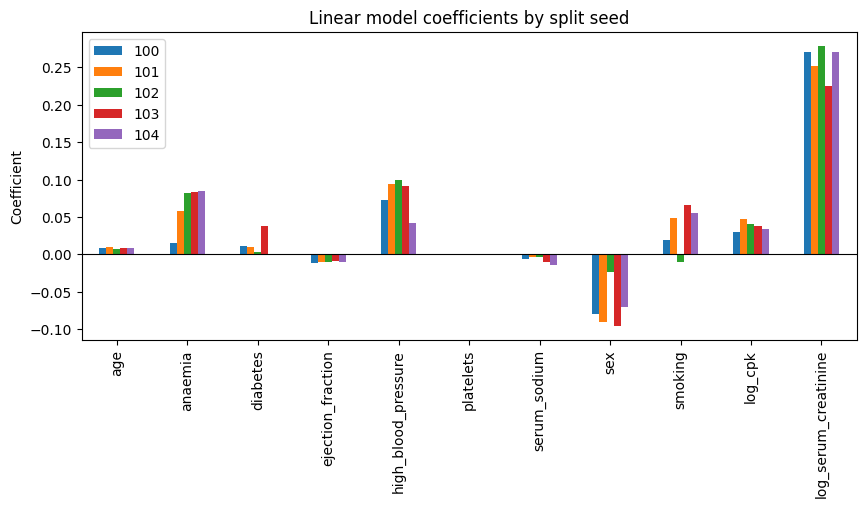

In [3]:
# Alternative seeds
alt_seeds = [101, 102, 103, 104]
all_seeds = [main_seed] + alt_seeds

trees, lms = {100: tree_main}, {100: lm_main}

# Store performance results, starting with seed 100
results = [
    {"seed": 100, "model": "Tree", **evaluate(tree_main, X_test_main, y_test_main)},
    {"seed": 100, "model": "Linear", **evaluate(lm_main, X_test_main, y_test_main)},
]

# Predictions from the alternative models on the SEED-100 test set
tree_pred_alt, lm_pred_alt = {}, {}

# Refit both models for each alternative seed
for seed in alt_seeds:
    tree, lm, X_test, y_test = fit_models(seed)
    trees[seed], lms[seed] = tree, lm

    # Evaluate on this seed's own test set
    results.append({"seed": seed, "model": "Tree", **evaluate(tree, X_test, y_test)})
    results.append({"seed": seed, "model": "Linear", **evaluate(lm, X_test, y_test)})

    # Set aside predictions on the seed-100 test set
    tree_pred_alt[seed] = tree.predict(X_test_main)
    lm_pred_alt[seed] = lm.predict(X_test_main)

# Performance across seeds
display(pd.DataFrame(results).pivot(index="seed", columns="model"))

# Print each tree so the splits are easy to compare side by side
for seed in all_seeds:
    print(f"===== Tree, seed {seed} =====")
    print(export_text(trees[seed], feature_names=list(X.columns), decimals=2))

# Checking how much each feature contributes to each tree's splits
display(pd.DataFrame({s: trees[s].feature_importances_ for s in all_seeds},
                     index=X.columns).round(3))

# Checking differences between linear model coefficients
coefs = pd.DataFrame({s: lms[s].coef_ for s in all_seeds}, index=X.columns)
coefs["sd across seeds"] = coefs.std(axis=1)
display(coefs.round(4))

# Bar chart
coefs.drop(columns="sd across seeds").plot.bar(figsize=(10, 4))
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Linear model coefficients by split seed")
plt.ylabel("Coefficient")
plt.show()

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [4]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]